# M11a · SB-LN pilot: can a shared-basis LayerNorm adapter be trained to full-LayerNorm accuracy?

**Why.** M10a showed that cutting trained LayerNorm changes down to rank r after training fails (r = 8: seen 77.5, FaceShifter 66.3, DFD 88.7, against 95.6 / 92.9 / 96.7). That is a worst case, because those models never had to work inside a subspace. This pilot trains SB-LN **from the start** and changes nothing else.

**Adapter (SB-LN).** For every LayerNorm l (50 of them):

γ_l = γ_l⁰ + B_γ a_l,  β_l = β_l⁰ + B_β b_l

B_γ, B_β ∈ ℝ^{1024×r} are shared by all 50 LayerNorms, a_l, b_l ∈ ℝ^r belong to LayerNorm l, γ⁰, β⁰ are CLIP's values (frozen). Init: a = b = 0 (the model starts exactly at CLIP), B = random orthonormal columns × √(1024 / r), so one Adam step changes a LayerNorm by about as much as in full LayerNorm tuning.

**Everything else is M4 λ = ∞:** linear head (2,050), M1 loss (CE + 0.1 align + 0.5 uniform), pure-generator blocks with round-robin reals, 10 epochs × 900 steps, same learning-rate cycle, seed 0. So the reference is M4 λ = ∞ (full LayerNorms): seen 96.41, NT 87.90, FaceShifter 90.53, DFD 96.05.

**How it is trained.** SB-LN rebuilds the 104,450 effective numbers (50 LayerNorms + head) before each forward pass, so the M4 forward/backward is reused unchanged. The gradient on the effective numbers is mapped to the SB-LN parameters by the chain rule (∂L/∂A = G_γ B_γ, ∂L/∂B_γ = G_γᵀ A, same for β); 4.2 checks this against finite differences.

**Runs** (priority order): r = 8 (19,234 trainable), r = 32 (70,786), r = 16 (36,418). If r = 8 passes, r = 16 is optional; if r = 32 fails, SB-LN is out.

**Decision rule (fixed before training).** The smallest r whose deployed model stays within **1.0** of full LayerNorms on seen and on FaceShifter, and within **0.5** on DFD. NeuralTextures is reported, not used in the rule.

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports | seconds |
| 2. Data | crops in RAM, round-robin loader (as M4) | ~1–8 min |
| 3. Model | detector, SB-LN, parameter report | ~1 min |
| 4. Training | checks, rank sweep, resumable | ~1.3 h per rank, ~4 h for all 3 |
| 5. Evaluation | FF++ test, DFD, vs full LayerNorms, decision | ~5 min per rank (DFD) |
| 6. Send results back | push this notebook | – |

## 1. Setup

### 1.1 Settings

Training settings are copied from M4. `RANKS` is in priority order. Results go to `runs/m11a/`.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
FACES_DFD = DATA_ROOT / "faces_dfd"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M11A_DIR = RUNS_ROOT / "m11a"
M4_DIR = RUNS_ROOT / "m4"
M10A_DIR = RUNS_ROOT / "m10a"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G = len(TRAIN_GENERATORS)

# identical to M4
ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

# SB-LN pilot
RANKS = [8, 32, 16]          # priority order
BASIS_INIT = "orthonormal columns x sqrt(width / r); coefficients 0"
RUN_DFD = True
TOL = {"seen": 1.0, "FSh": 1.0, "DFD": 0.5}   # allowed drop vs full LayerNorms, fixed before training

REF_DIR = M4_DIR / f"gbla_laminf_{ARCH}_seed{SEED}"    # full LayerNorms, same data order, loss and schedule
REF_DFD = 96.05                                          # M8b, M4 lambda = inf
REF_CHANGE = {"gamma": 16.6, "beta": 15.7}               # M10a: Frobenius norm of the trained change, M4 lambda = inf

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
    "method": "SB-LN, pooled (no private offsets), linear head",
    "adapter": "gamma_l = gamma0_l + Bg a_l, beta_l = beta0_l + Bb b_l (bases shared by all 50 LayerNorms)",
    "basis_init": BASIS_INIT,
    "reals": "round-robin, fixed for the run, 1/G per generator (as M4)",
    "deployed": "Bg, Bb, a, b, head",
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV}"
assert (REF_DIR / "results.json").exists(), f"M4 lambda = inf results missing: {REF_DIR}"
M11A_DIR.mkdir(parents=True, exist_ok=True)
print("M11a runs go to:", M11A_DIR)
print("ranks:", RANKS)

M11a runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m11a
ranks: [8, 32, 16]


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M11a needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,8
data loader workers,7
free RAM for this job (GB),1030.2


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [3]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [4]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [00:18<00:00, 6356.90it/s]


train: 115,200 crops, 17.3 GB in RAM, 1.1 min (1790 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:02<00:00, 2181.99it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.1 min (1763 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:10<00:00, 2644.23it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.2 min (1804 crops/s from disk)


### 2.3 Round-robin loader

Each training generator owns all of its fakes and a **fixed** 1/G slice of the training reals (round-robin by row order, seed 0). A real crop is never shared across generators, so Σ_g L_g is one pass over the M1 training set. One epoch = G blocks of 225 steps = 900 steps, the same number of images as one M1 epoch. Block order inside an epoch is shuffled by (seed, epoch); order inside a block depends only on (seed, generator, epoch).

In [5]:
# 2.3 Round-robin loader
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class RoundRobinSampler(Sampler):
    """One epoch = one block per training generator, in an order fixed by (seed, epoch)."""

    def __init__(self, df, seed):
        self.seed = seed
        self.epoch = 0
        gen = df.generator.values
        real_idx = np.flatnonzero(gen == "original")
        # fixed split: real row r goes to generator r % G
        self.blocks = {}
        for k, g in enumerate(TRAIN_GENERATORS):
            fakes = np.flatnonzero(gen == g)
            reals = real_idx[k::G][: len(fakes) // G]
            self.blocks[g] = (fakes, reals)
        self.n_per = len(self.blocks[TRAIN_GENERATORS[0]][0]) + len(self.blocks[TRAIN_GENERATORS[0]][1])

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order_rng = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(TRAIN_GENERATORS)
        order_rng.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n_per * G


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = RoundRobinSampler(train_df, SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
owned = {SHORT[g]: (len(f), len(r)) for g, (f, r) in train_sampler.blocks.items()}
print("fakes / reals owned by each generator:", owned)
print(f"steps per epoch: {len(train_loader)}  (M1 was 900);  workers: {NUM_WORKERS}")
assert len(train_loader) == 900, len(train_loader)

fakes / reals owned by each generator: {'DF': (23040, 5760), 'F2F': (23040, 5760), 'FS': (23040, 5760), 'NT': (23040, 5760)}
steps per epoch: 900  (M1 was 900);  workers: 7


### 2.4 Data-loading speed

Same measurement as M4. The printed hours are for **one rank** (10 epochs × 900 steps).

In [6]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per rank ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",2.7
data loading speed (img/s),996
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),7.6
estimated hours per rank (10 epochs),1.3


## 3. Model

### 3.1 Detector

Same detector as M1/M4. The 104,450 numbers of the 50 LayerNorms and the head are still written by `set_flat` before each forward pass; with SB-LN they are computed from the bases and coefficients instead of being trained directly.

In [7]:
# 3.1 Detector (as in M1)
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"trainable numbers P = {P:,}")
if ARCH == "ViT-L-14":
    assert P == 104_450

trainable numbers P = 104,450


### 3.2 SB-LN and parameter report

`SBLNState` holds the trained SB-LN numbers: B_γ, B_β (1024 × r each), A = [a_1 … a_50], C = [b_1 … b_50] (50 × r each) and the head. `theta()` rebuilds the 104,450 effective numbers. `grads()` maps the gradient on those numbers to the SB-LN parameters.

Frozen numbers now include CLIP's own LayerNorm values (102,400), because they are no longer trained.

In [8]:
# 3.2 SB-LN parameterisation and parameter report
WIDTH = model.encoder.transformer.width
SLICES, offset = {}, 0
for n, p in PARAMS:
    SLICES[n] = slice(offset, offset + p.numel())
    offset += p.numel()
LN_MODULES = [n[:-len(".weight")] for n in PARAM_NAMES if n.endswith(".weight") and not n.startswith("head")]
N_LN = len(LN_MODULES)
assert N_LN == 50, N_LN


def rows_index(suffix):
    return torch.stack([torch.arange(SLICES[m + suffix].start, SLICES[m + suffix].stop) for m in LN_MODULES]).to(DEVICE)


GAMMA_IDX, BETA_IDX = rows_index(".weight"), rows_index(".bias")          # 50 x 1024 positions in theta
HEAD_IDX = torch.cat([torch.arange(SLICES[n].start, SLICES[n].stop) for n in PARAM_NAMES if n.startswith("head")]).to(DEVICE)
assert GAMMA_IDX.shape == (N_LN, WIDTH) and HEAD_IDX.numel() == 2050
G0, B0 = THETA0[GAMMA_IDX].clone(), THETA0[BETA_IDX].clone()


def sbln_count(r):
    return 2 * WIDTH * r + 2 * N_LN * r + HEAD_IDX.numel()


class SBLNState:
    """Shared bases Bg, Bb (width x r), coefficients A, C (50 x r) and the head. Device tensors, float32."""
    KEYS = ("Bg", "Bb", "A", "C", "head")

    def __init__(self, r, seed=SEED):
        self.r = r
        gen = torch.Generator().manual_seed(seed)
        scale = math.sqrt(WIDTH / r)

        def basis():
            q, _ = torch.linalg.qr(torch.randn(WIDTH, r, generator=gen))
            return (q * scale).to(DEVICE)

        self.p = {"Bg": basis(), "Bb": basis(),
                  "A": torch.zeros(N_LN, r, device=DEVICE), "C": torch.zeros(N_LN, r, device=DEVICE),
                  "head": THETA0[HEAD_IDX].clone()}

    def numel(self):
        return sum(v.numel() for v in self.p.values())

    def theta(self, p=None):
        p = self.p if p is None else p
        t = THETA0.clone()
        t[GAMMA_IDX] = G0 + p["A"] @ p["Bg"].T
        t[BETA_IDX] = B0 + p["C"] @ p["Bb"].T
        t[HEAD_IDX] = p["head"]
        return t

    def grads(self, grad):
        """Chain rule from the gradient on the 104,450 effective numbers to the SB-LN parameters."""
        Gg, Gb, p = grad[GAMMA_IDX], grad[BETA_IDX], self.p
        return {"A": Gg @ p["Bg"], "Bg": Gg.T @ p["A"], "C": Gb @ p["Bb"], "Bb": Gb.T @ p["C"],
                "head": grad[HEAD_IDX]}

    def change_norms(self):
        p = self.p
        return {"gamma": float((p["A"] @ p["Bg"].T).norm()), "beta": float((p["C"] @ p["Bb"].T).norm())}

    def save(self):
        return {"rank": self.r, "phi": {k: v.detach().cpu() for k, v in self.p.items()},
                "theta": self.theta().detach().cpu()}

    def load(self, obj):
        assert obj["rank"] == self.r, (obj["rank"], self.r)
        self.p = {k: obj["phi"][k].to(DEVICE).float() for k in self.KEYS}


TOTAL_ALL = sum(p.numel() for p in model.parameters())
FROZEN_SBLN = TOTAL_ALL - HEAD_IDX.numel()          # backbone incl. CLIP's gamma0 / beta0
rows = [{"model": "full LayerNorms + linear head (M4)", "trainable (deployed)": P,
         "frozen": TOTAL_ALL - P, "total": TOTAL_ALL}]
for r in sorted(RANKS):
    assert SBLNState(r).numel() == sbln_count(r)
    rows.append({"model": f"SB-LN r={r} + linear head", "trainable (deployed)": sbln_count(r),
                 "frozen": FROZEN_SBLN, "total": FROZEN_SBLN + sbln_count(r)})
param_report = pd.DataFrame(rows).set_index("model")
param_report["trainable %"] = (100 * param_report["trainable (deployed)"] / param_report["total"]).round(4)
param_report["vs full LN"] = (P / param_report["trainable (deployed)"]).round(2).astype(str) + "x fewer"
display(param_report)

,trainable (deployed),frozen,total,trainable %,vs full LN
model,,,,,
full LayerNorms + linear head (M4),104450,303077376,303181826,0.0345,1.0x fewer
SB-LN r=8 + linear head,19234,303179776,303199010,0.0063,5.43x fewer
SB-LN r=16 + linear head,36418,303179776,303216194,0.0120,2.87x fewer
SB-LN r=32 + linear head,70786,303179776,303250562,0.0233,1.48x fewer


## 4. Training

### 4.1 Loss, schedule, SB-LN step

Loss and learning-rate cycle as M1/M4. One step: rebuild θ from SB-LN, forward/backward exactly as M4, map the gradient to (B_γ, B_β, A, C, head) by the chain rule, one Adam step (weight decay 0) per parameter tensor, each with its own step counter. There are no private offsets in this pilot.

In [9]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def adam_step(param, grad, m, v, t, lr):
    """One AdamW step with weight decay 0. m, v, t are updated in place. t is a 0-dim tensor."""
    b1, b2, eps = 0.9, 0.999, 1e-8
    t += 1
    m.mul_(b1).add_(grad, alpha=1 - b1)
    v.mul_(b2).addcmul_(grad, grad, value=1 - b2)
    mhat = m / (1 - b1 ** t)
    vhat = v / (1 - b2 ** t)
    param.addcdiv_(mhat, vhat.sqrt().add_(eps), value=-lr)


class AdamSlots:
    def __init__(self, state):
        self.m = {k: torch.zeros_like(v) for k, v in state.p.items()}
        self.v = {k: torch.zeros_like(v) for k, v in state.p.items()}
        self.t = {k: torch.zeros((), dtype=torch.long, device=DEVICE) for k in state.p}

    def state_dict(self):
        return {"m": {k: v.cpu() for k, v in self.m.items()}, "v": {k: v.cpu() for k, v in self.v.items()},
                "t": {k: int(v) for k, v in self.t.items()}}

    def load_state_dict(self, s):
        for k in self.m:
            self.m[k].copy_(s["m"][k].to(DEVICE))
            self.v[k].copy_(s["v"][k].to(DEVICE))
            self.t[k].fill_(s["t"][k])


def train_step_sbln(state, opt, x, y, lr):
    set_flat(state.theta())
    model.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, f = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), f.float(), y)
    loss.backward()
    grads = state.grads(flat_grad().detach())        # all gradients use the parameters before the step
    for k, gk in grads.items():
        adam_step(state.p[k], gk, opt.m[k], opt.v[k], opt.t[k], lr)
    return parts, ce_each


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


@torch.no_grad()
def predict(theta, df, images=None, desc="predict"):
    set_flat(theta.detach())
    model.eval()
    probs = []
    if images is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(images[s:s + EVAL_BATCH]))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
        })
    return pd.DataFrame(rows).round(2)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def run_dir_for(r):
    return M11A_DIR / f"sbln_r{r}_{ARCH}_seed{SEED}"


def check_config(run_dir, config):
    path = run_dir / "config.json"
    dumped = json.loads(json.dumps(config))
    if path.exists():
        assert json.loads(path.read_text()) == dumped, f"{run_dir} settings differ; delete the folder to restart"
    else:
        path.write_text(json.dumps(dumped, indent=1))

### 4.2 Correctness check (before the sweep)

1. At the start (A = C = 0) the rebuilt θ equals θ0 exactly, so the model is CLIP with the untrained head.
2. The first step moves A, C and the head but not the bases (their gradient Gᵀ A is 0 while A = 0, as in LoRA); the second step moves the bases too.
3. The chain-rule gradient matches a finite-difference slope along a random direction of all SB-LN parameters (A, C set to small random values first so every block has a gradient), at several step sizes.
4. The rebuilt LayerNorm change has rank ≤ r.

In [10]:
# 4.2 Correctness check
R_CHECK = min(RANKS)
state = SBLNState(R_CHECK)
start_ok = torch.equal(state.theta(), THETA0)

check_rows = pd.concat([
    train_df[train_df.generator == "original"].iloc[:2],
    train_df[train_df.generator == TRAIN_GENERATORS[0]].iloc[:2],
])
check_ds = FaceDataset(check_rows.reset_index(drop=True), train=False, images=None)
xs, ys = [], []
for i in range(4):
    x, y, _ = check_ds[i]
    xs.append(x); ys.append(y)
check_x = torch.stack(xs).to(DEVICE)
check_y = torch.stack(ys).to(DEVICE)

# steps 1 and 2
opt = AdamSlots(state)
before = {k: v.clone() for k, v in state.p.items()}
train_step_sbln(state, opt, check_x, check_y, LR_MAX)
moved_1 = {k: not torch.equal(before[k], state.p[k]) for k in state.p}
after_1 = {k: v.clone() for k, v in state.p.items()}
train_step_sbln(state, opt, check_x, check_y, LR_MAX)
moved_2 = {k: not torch.equal(after_1[k], state.p[k]) for k in state.p}
change = state.p["A"].double() @ state.p["Bg"].double().T   # float64 product: TF32 rounding would add tiny extra singular values
rank_ok = int(torch.linalg.matrix_rank(change, rtol=1e-9)) <= R_CHECK

# finite differences along a random direction of (Bg, Bb, A, C, head), fp32, eval mode
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
model.eval()
state = SBLNState(R_CHECK)
with torch.no_grad():
    state.p["A"].normal_(0, 1e-3)
    state.p["C"].normal_(0, 1e-3)
direction = {k: torch.randn_like(v) for k, v in state.p.items()}
norm = math.sqrt(sum(float(d.pow(2).sum()) for d in direction.values()))
direction = {k: d / norm for k, d in direction.items()}
set_flat(state.theta())
model.zero_grad(set_to_none=True)
logits, f = model(check_x)
loss, _, _ = compute_loss(logits.float(), f.float(), check_y)
loss.backward()
grads = state.grads(flat_grad().detach())
auto = sum(float((grads[k] * direction[k]).sum()) for k in grads)
base = {k: v.clone() for k, v in state.p.items()}


def loss_at(shift):
    set_flat(state.theta({k: base[k] + shift * direction[k] for k in base}))
    with torch.no_grad():
        logits, f = model(check_x)
        value, _, _ = compute_loss(logits.float(), f.float(), check_y)
    return value.item()


fd_rows = []
for eps in (1e-2, 3e-3, 1e-3, 3e-4):
    fd = (loss_at(eps) - loss_at(-eps)) / (2 * eps)
    fd_rows.append({"eps": eps, "finite-difference slope": fd, "chain-rule slope": auto,
                    "relative error": abs(fd - auto) / max(abs(fd), abs(auto), 1e-12)})
fd_table = pd.DataFrame(fd_rows)
best_rel = float(fd_table["relative error"].min())
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
model.train()

checks = {
    "start theta equals theta0": bool(start_ok),
    "step 1 moves A, C, head": all(moved_1[k] for k in ("A", "C", "head")),
    "step 1 leaves the bases": not (moved_1["Bg"] or moved_1["Bb"]),
    "step 2 moves the bases": moved_2["Bg"] and moved_2["Bb"],
    "LayerNorm change has rank <= r": bool(rank_ok),
    "finite differences agree": best_rel < 0.02,
}
display(pd.Series(checks, name="value").to_frame())
display(fd_table.style.format({"eps": "{:g}", "finite-difference slope": "{:.6g}",
                               "chain-rule slope": "{:.6g}", "relative error": "{:.2e}"}))
failed = [name for name, ok in checks.items() if not ok]
assert not failed, "failed checks: " + ", ".join(failed)
print("SB-LN CHECKS OK")
del state, opt
torch.cuda.empty_cache()

,value
start theta equals theta0,True
"step 1 moves A, C, head",True
step 1 leaves the bases,True
step 2 moves the bases,True
LayerNorm change has rank <= r,True
finite differences agree,True


,eps,finite-difference slope,chain-rule slope,relative error
0,0.01,-0.00413656,-0.00410296,8.12e-03
1,0.003,-0.00427663,-0.00410296,4.06e-02
2,0.001,-0.00415742,-0.00410296,1.31e-02
3,0.0003,-0.00203649,-0.00410296,5.04e-01


SB-LN CHECKS OK


### 4.3 Rank sweep (resumable)

Each rank gets `runs/m11a/sbln_r<r>_.../` with `config.json`, `epoch_XX.pt` (SB-LN parameters and the rebuilt θ), `last.pt` (plus Adam slots and history), `test_predictions.csv`, `results.json`. The epoch line also prints the size of the LayerNorm change (‖ΔΓ‖, ‖ΔΒ‖); full LayerNorm tuning reached about 16.6 and 15.7.

**Resume:** run 1.1–4.1 and this cell. Finished ranks are skipped. Kernel → Interrupt is safe between epochs. If time is short, stop after r = 8 and r = 32.

In [11]:
# 4.3 Rank sweep (resumable)
def train_rank(r):
    run_dir = run_dir_for(r)
    run_dir.mkdir(parents=True, exist_ok=True)
    check_config(run_dir, {**COMMON_CONFIG, "rank": r, "trainable": sbln_count(r)})
    state = SBLNState(r)
    opt = AdamSlots(state)
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        state.load(ckpt["sbln"])
        opt = AdamSlots(state)
        opt.load_state_dict(ckpt["adam"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"\n===== rank {r} ({sbln_count(r):,} trainable): {start_epoch}/{EPOCHS} epochs done =====")

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"r {r} ep {epoch + 1}/{EPOCHS}", leave=False)):
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            fake_codes = gen[gen != GEN_CODE["original"]]
            assert len(fake_codes) > 0 and torch.all(fake_codes == fake_codes[0]), "mixed-generator batch"
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            parts, ce_each = train_step_sbln(state, opt, x, y, lr)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(gen, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(gen, minlength=len(CATEGORIES))
            n_steps += 1

        val_table = metrics_table(predict(state.theta(), val_df, images["val"], desc="val"))
        change = state.change_norms()
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k])
                    for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        row.update({"|dGamma|": change["gamma"], "|dBeta|": change["beta"],
                    "val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(state.save(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "sbln": state.save(), "adam": opt.state_dict(), "history": history},
                    run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        pred = predict(state.theta(), test_df, images["test"], desc="test")
        pred.to_csv(run_dir / "test_predictions.csv", index=False)
        table = metrics_table(pred)
        display(table)
        (run_dir / "results.json").write_text(json.dumps(
            {"rank": r, "trainable": sbln_count(r), "test": table.to_dict(orient="records"),
             "history": history, "change_norms": state.change_norms()}, indent=1))
    del state, opt
    torch.cuda.empty_cache()


for r in RANKS:
    train_rank(r)
print("sweep finished")


===== rank 8 (19,234 trainable): 0/10 epochs done =====


epoch 1 | lr (end) 0.0002997 | loss -0.6807 | ce 0.5444 | align 1.385 | uniform -2.727 | CE real 0.9796 | CE DF 0.2757 | CE F2F 0.478 | CE FS 0.3375 | CE NT 0.651 | |dGamma| 16.68 | |dBeta| 19.56 | val frame AUC 80.27 | val video AUC 82.89 | minutes 8.035


epoch 2 | lr (end) 0.0002913 | loss -1.311 | ce 0.3978 | align 1.905 | uniform -3.799 | CE real 0.9681 | CE DF 0.222 | CE F2F 0.2827 | CE FS 0.1916 | CE NT 0.3244 | |dGamma| 22.06 | |dBeta| 25.69 | val frame AUC 83.88 | val video AUC 86.18 | minutes 8.115


epoch 3 | lr (end) 0.0002661 | loss -1.409 | ce 0.3346 | align 1.938 | uniform -3.875 | CE real 0.8593 | CE DF 0.141 | CE F2F 0.2538 | CE FS 0.1464 | CE NT 0.2727 | |dGamma| 23.43 | |dBeta| 27.55 | val frame AUC 84.75 | val video AUC 87.04 | minutes 7.985


epoch 4 | lr (end) 0.0002275 | loss -1.438 | ce 0.3095 | align 1.939 | uniform -3.884 | CE real 0.8262 | CE DF 0.09341 | CE F2F 0.2186 | CE FS 0.1244 | CE NT 0.285 | |dGamma| 25.62 | |dBeta| 29 | val frame AUC 86.25 | val video AUC 89.01 | minutes 8.003


epoch 5 | lr (end) 0.0001802 | loss -1.452 | ce 0.3055 | align 1.953 | uniform -3.905 | CE real 0.8387 | CE DF 0.1083 | CE F2F 0.2123 | CE FS 0.1228 | CE NT 0.2453 | |dGamma| 26.35 | |dBeta| 29.45 | val frame AUC 86.12 | val video AUC 88.61 | minutes 8


... (27 outputs left out)

epoch 9 | lr (end) 1.876e-05 | loss -1.474 | ce 0.2867 | align 1.95 | uniform -3.912 | CE real 0.7226 | CE DF 0.07205 | CE F2F 0.1905 | CE FS 0.08068 | CE NT 0.3678 | |dGamma| 25.52 | |dBeta| 27.6 | val frame AUC 90.69 | val video AUC 92.82 | minutes 8.076


epoch 10 | lr (end) 1e-05 | loss -1.447 | ce 0.3095 | align 1.946 | uniform -3.903 | CE real 0.776 | CE DF 0.0507 | CE F2F 0.1705 | CE FS 0.0554 | CE NT 0.4947 | |dGamma| 25.64 | |dBeta| 27.7 | val frame AUC 90.82 | val video AUC 93.05 | minutes 7.995


,test set,status,frame AUC,video AUC,video acc @0.5
0,seen combined (DF+F2F+FS+NT),seen,91.71,94.54,87.14
1,Deepfakes,seen,98.53,99.49,93.57
2,Face2Face,seen,94.81,97.86,91.79
3,FaceSwap,seen,98.24,99.60,93.57
4,NeuralTextures,seen,75.27,81.21,70.71
5,FaceShifter,UNSEEN,86.09,92.25,83.93


sweep finished


## 5. Evaluation

### 5.1 FF++ test and DFD

FF++ test video AUC of every finished rank next to full LayerNorms (M4 λ = ∞, same training setup) and GBLA λ = 0.01 for context, plus the M10a truncation number at the same rank (cut after training) to show how much training inside the subspace recovers. DFD (109,454 crops, cross-dataset) is scored for every finished rank and stored in `results.json`.

In [12]:
# 5.1 FF++ test and DFD
def video_auc_from_records(records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"seen": t.iloc[0]["video AUC"]}
    row.update({SHORT[g]: t.loc[g, "video AUC"] for g in ALL_GENERATORS})
    return row


DFD_IMAGES, dfd_index = None, None


@torch.no_grad()
def dfd_video_auc(theta):
    global DFD_IMAGES, dfd_index
    if DFD_IMAGES is None:
        dfd_index = pd.read_csv(DFD_INDEX)
        paths = [FACES_DFD / p for p in dfd_index.path]
        DFD_IMAGES = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

        def work(k):
            DFD_IMAGES[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

        with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
            list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc="DFD crops -> RAM", mininterval=5))
    set_flat(theta)
    model.eval()
    probs = []
    for s in tqdm(range(0, len(DFD_IMAGES), EVAL_BATCH), desc="DFD", leave=False):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, _ = model(to_model_input(DFD_IMAGES[s:s + EVAL_BATCH]))
        probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    vid = dfd_index.assign(prob=torch.cat(probs).numpy()).groupby("video_id", as_index=False).agg(
        label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


rows = []
ref = json.loads((REF_DIR / "results.json").read_text())
rows.append({"model": "full LayerNorms (M4 λ=∞)", "trainable": P, **video_auc_from_records(ref["test"]),
             "DFD": REF_DFD, "|dGamma|": REF_CHANGE["gamma"], "|dBeta|": REF_CHANGE["beta"]})
gbla = M4_DIR / f"gbla_lam0.01_{ARCH}_seed{SEED}" / "results.json"
if gbla.exists():
    rows.append({"model": "GBLA λ=0.01 (context)", "trainable": P,
                 **video_auc_from_records(json.loads(gbla.read_text())["test"]), "DFD": 96.71})
trunc = pd.read_csv(M10A_DIR / "truncation_results.csv") if (M10A_DIR / "truncation_results.csv").exists() else None

histories = {}
for r in sorted(RANKS):
    path = run_dir_for(r) / "results.json"
    if not path.exists():
        print(f"rank {r}: not finished")
        continue
    res = json.loads(path.read_text())
    if RUN_DFD and "dfd_video_auc" not in res:
        st = SBLNState(r)
        st.load(load(run_dir_for(r) / f"epoch_{EPOCHS:02d}.pt"))
        res["dfd_video_auc"] = dfd_video_auc(st.theta())
        path.write_text(json.dumps(res, indent=1))
    histories[r] = res["history"]
    rows.append({"model": f"SB-LN r={r}", "trainable": res["trainable"], **video_auc_from_records(res["test"]),
                 "DFD": res.get("dfd_video_auc", float("nan")),
                 "|dGamma|": res["change_norms"]["gamma"], "|dBeta|": res["change_norms"]["beta"]})
    if trunc is not None:
        t = trunc[(trunc.key == f"ff|lam_inf|additive|{r}")]
        if len(t):
            rows.append({"model": f"  (M10a: λ=∞ cut to r={r} after training)", "trainable": float("nan"),
                         **{c: float(t[c].iloc[0]) for c in ("seen", "DF", "F2F", "FS", "NT", "FSh")}})
DFD_IMAGES = None
results_table = pd.DataFrame(rows).set_index("model")
display(results_table.round(2))
results_table.to_csv(M11A_DIR / "results_table.csv")

DFD crops -> RAM: 100%|██████████| 109454/109454 [01:02<00:00, 1746.75it/s]
                                                      

,trainable,seen,DF,F2F,FS,NT,FSh,DFD,|dGamma|,|dBeta|
model,,,,,,,,,,
full LayerNorms (M4 λ=∞),104450.0,96.41,99.72,98.66,99.34,87.90,90.53,96.05,16.60,15.70
GBLA λ=0.01 (context),104450.0,95.55,99.43,98.55,99.17,85.06,92.91,96.71,NaN,NaN
SB-LN r=8,19234.0,93.10,99.61,96.35,99.38,77.08,92.09,94.14,28.71,30.83
(M10a: λ=∞ cut to r=8 after training),NaN,78.64,94.29,70.71,94.05,55.52,68.80,NaN,NaN,NaN
SB-LN r=16,36418.0,94.54,99.49,97.86,99.60,81.21,92.25,95.15,25.64,27.70
(M10a: λ=∞ cut to r=16 after training),NaN,85.38,98.08,85.51,98.43,59.50,83.20,NaN,NaN,NaN
SB-LN r=32,70786.0,94.81,99.65,98.18,99.72,81.69,92.06,95.31,24.24,25.17
(M10a: λ=∞ cut to r=32 after training),NaN,91.04,98.89,96.04,99.41,69.83,83.64,NaN,NaN,NaN


### 5.2 Training curves

Validation video AUC per epoch and the size of the LayerNorm change. If SB-LN's change stays far below full LayerNorm tuning (about 16.6 / 15.7), the basis scale or learning rate is too small rather than the rank too low.

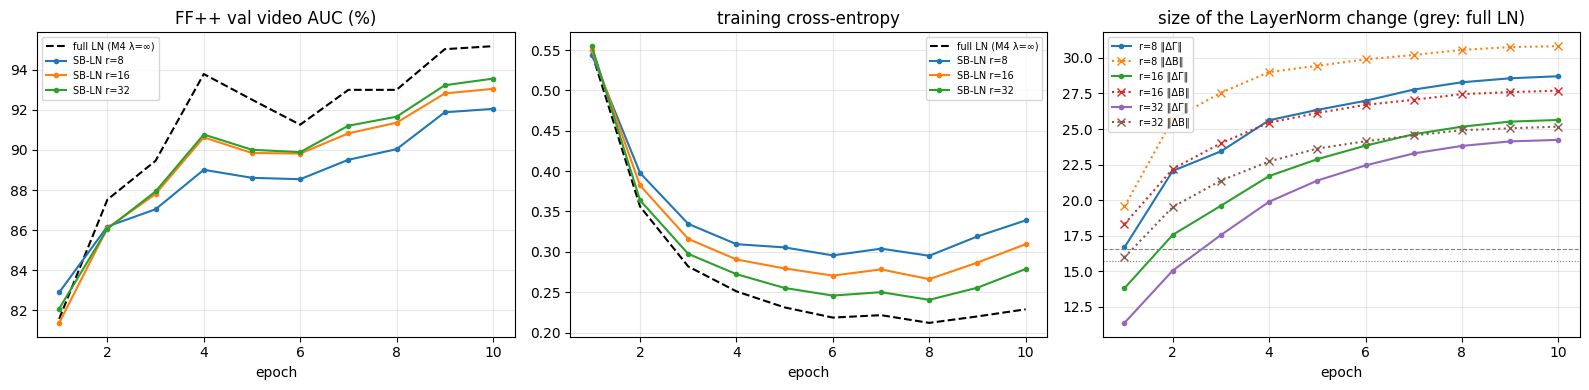

In [13]:
# 5.2 Training curves
assert histories, "no finished ranks"
ref_hist = pd.DataFrame(ref["history"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ref_hist.epoch, ref_hist["val video AUC"], "k--", label="full LN (M4 λ=∞)")
axes[1].plot(ref_hist.epoch, ref_hist["ce"], "k--", label="full LN (M4 λ=∞)")
for r, hist in histories.items():
    h = pd.DataFrame(hist)
    axes[0].plot(h.epoch, h["val video AUC"], marker=".", label=f"SB-LN r={r}")
    axes[1].plot(h.epoch, h["ce"], marker=".", label=f"SB-LN r={r}")
    axes[2].plot(h.epoch, h["|dGamma|"], marker=".", label=f"r={r} ‖ΔΓ‖")
    axes[2].plot(h.epoch, h["|dBeta|"], marker="x", ls=":", label=f"r={r} ‖ΔΒ‖")
axes[2].axhline(REF_CHANGE["gamma"], c="gray", ls="--", lw=0.8)
axes[2].axhline(REF_CHANGE["beta"], c="gray", ls=":", lw=0.8)
axes[0].set_title("FF++ val video AUC (%)"); axes[1].set_title("training cross-entropy")
axes[2].set_title("size of the LayerNorm change (grey: full LN)")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M11A_DIR / "curves.png", dpi=150); plt.show()

### 5.3 Decision

The smallest finished rank within the tolerances fixed in 1.1 (seen and FaceShifter −1.0, DFD −0.5 vs full LayerNorms) is the SB-LN rank for M11b (private offsets on the full LayerNorm values, offset-norm weighted GBRA loss, prototype head).

In [14]:
# 5.3 Decision and summary
full = results_table.loc["full LayerNorms (M4 λ=∞)"]
verdict = {}
for r in sorted(histories):
    row = results_table.loc[f"SB-LN r={r}"]
    gaps = {"seen": row.seen - full.seen, "FSh": row.FSh - full.FSh, "NT": row.NT - full.NT,
            "DFD": row.DFD - full.DFD}
    ok = gaps["seen"] >= -TOL["seen"] and gaps["FSh"] >= -TOL["FSh"] and (
        not RUN_DFD or gaps["DFD"] >= -TOL["DFD"])
    verdict[r] = {"trainable": int(row.trainable), **{f"gap {k}": round(v, 2) for k, v in gaps.items()}, "passes": bool(ok)}
verdict_table = pd.DataFrame(verdict).T
display(verdict_table)
passing = [r for r, v in verdict.items() if v["passes"]]
chosen = min(passing) if passing else None
if chosen is not None:
    print(f"DECISION: SB-LN rank {chosen} ({sbln_count(chosen):,} trainable with the linear head; "
          f"{sbln_count(chosen) - 2050 + 2:,} with the prototype head) -> use it in M11b")
else:
    print("DECISION: no finished rank is within tolerance -> SB-LN does not reach full-LayerNorm accuracy at these ranks")

(M11A_DIR / "summary.json").write_text(json.dumps({
    "question": "can SB-LN trained from scratch match full LayerNorm tuning (M4 lambda = inf)",
    "parameters": param_report.reset_index().astype(str).to_dict("records"),
    "results": results_table.round(3).reset_index().astype(str).to_dict("records"),
    "tolerances": TOL, "verdict": {str(k): v for k, v in verdict.items()}, "chosen_rank": chosen,
}, indent=2, ensure_ascii=False))

,trainable,gap seen,gap FSh,gap NT,gap DFD,passes
8,19234,-3.31,1.56,-10.82,-1.91,False
16,36418,-1.87,1.72,-6.69,-0.9,False
32,70786,-1.6,1.53,-6.21,-0.74,False


DECISION: no finished rank is within tolerance -> SB-LN does not reach full-LayerNorm accuracy at these ranks


3913